# Laboratorio 2 - Complejidad y busqueda de hiperparametros

Integrantes:
- Juan Felipe Saenz - 202311148
- Tomas Aguilera - 202321962

Este laboratorio retoma el caso de AlpesPlanck del Laboratorio 1. Ya no se va a repetir la exploracion ni la limpieza de datos porque eso se hizo en el Laboratorio 1 (el notebook "Laboratorio1_Regresion.ipynb"). Ahi se compararon tres formas de preparar los datos y la que mejor funciono fue el Modelo 3 (limpieza de valores fisicamente imposibles + ingenieria temporal a partir de la fecha).

Para este laboratorio exportamos ese mismo resultado (limpio) a dos archivos csv, "Datos Lab 2 Train.csv" y "Datos Lab 2 Test.csv", que corresponden exactamente al mismo train/test del Lab 1 (25% de test, random_state=42) ya con la limpieza aplicada. Ademas, revisando mas a fondo la variable presion_media (que en el Lab 1 se habia detectado con valores de hasta 9939 mbar pero nunca se corrigio en el codigo) y otras 3 mediciones puntuales con errores de sensor evidentes (viento_desv, rafaga_desv, viento_norte con un solo dato disparatado cada una), les aplicamos el mismo tratamiento de "fuera de rango fisico -> NaN" que ya se le habia hecho a humedad y direccion del viento en el Lab 1. Sin este ajuste la validacion cruzada de este laboratorio salia completamente inestable (un fold con RMSE de 150 en vez de 5) por esas pocas filas, lo cual no dejaba ver nada del efecto de la complejidad ni de la regularizacion.


## Importamos librerias

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV, KFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")


## Cargamos los datos ya limpios

Cargamos directamente los csv que ya tienen la limpieza y la ingenieria de caracteristicas del Modelo 3 del Lab 1 aplicada, tanto para train como para test.

In [2]:
train = pd.read_csv("Datos Lab 2 Train.csv")
test = pd.read_csv("Datos Lab 2 Test.csv")

X_train = train.drop(columns=["temp_max_manana"])
y_train = train["temp_max_manana"]
X_test = test.drop(columns=["temp_max_manana"])
y_test = test["temp_max_manana"]

print("Entrenamiento:", X_train.shape)
print("Test:", X_test.shape)


Entrenamiento: (1857, 25)
Test: (620, 25)


In [3]:
train.head()

,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,viento_min,...,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,mes_fecha,dia_sin,dia_cos,temp_max_manana
0,991.6231,990.06,992.85,0.9274,70.202400,42.560000,99.2,21.9879,4.58928,0.540000,...,0.0647,0.3583,79.7575,144.0,2011.0,163.0,NaN,NaN,NaN,20.25
1,999.3854,996.80,1001.95,1.8602,0.654419,44.320000,93.9,16.0069,1.27860,0.140000,...,0.0912,0.5734,80.9627,144.0,2013.0,233.0,8.0,-0.762114,-0.647443,23.88
2,993.4540,990.84,997.40,2.0934,63.992800,NaN,88.3,13.4818,1.54920,0.200000,...,0.1731,-0.9492,280.3334,144.0,2014.0,164.0,6.0,0.314942,-0.949111,17.92
3,982.9117,981.15,985.19,1.1768,57.785500,34.170000,76.2,13.8543,2.95990,12.013265,...,-2.5783,-1.0189,201.5640,NaN,2015.0,115.0,4.0,0.918121,-0.396299,19.81
4,997.0464,994.29,998.48,0.9378,84.814600,95.347648,73.2,4.8532,1.90410,0.360000,...,-0.7440,-1.4659,243.0910,144.0,2012.0,9.0,1.0,0.154204,0.988039,6.31


In [4]:
# Revisamos que efectivamente sigan quedando algunos NaN (los valores que se
# volvieron faltantes por estar fuera de rango fisico), estos se imputan
# dentro de cada pipeline con la mediana, igual que en el Lab 1
train.isnull().sum()[train.isnull().sum() > 0]


presion_media         63
presion_min           55
presion_max           44
presion_desv          56
humedad_media         56
humedad_min           72
humedad_max           70
humedad_desv          49
viento_media          72
viento_min            68
viento_max            50
viento_desv           52
rafaga_media          57
rafaga_min            53
rafaga_max            58
rafaga_desv          241
viento_norte          62
viento_este           46
direccion_viento      53
registros_del_dia     58
anio                  62
dia_del_anio          43
mes_fecha             60
dia_sin               60
dia_cos               60
dtype: int64

Como se ve, todavia quedan valores faltantes despues de la limpieza (los que se volvieron NaN por estar fuera de un rango fisicamente posible, mas los que ya venian faltantes desde el dato original). Por eso en todos los pipelines de este laboratorio el primer paso sigue siendo un `SimpleImputer` con la mediana, exactamente como se hizo en el Lab 1.

Definimos una sola particion de validacion cruzada (`KFold` con 5 folds, barajando los datos y con `random_state=42`) para usarla de forma consistente en todas las busquedas de hiperparametros del laboratorio, de manera que los resultados de los distintos modelos sean comparables entre si.

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

## Actividad 1 - Regresion polinomial

Armamos un pipeline que imputa los faltantes, escala las variables, genera caracteristicas polinomiales y ajusta una regresion lineal sobre esas caracteristicas. Buscamos con `GridSearchCV` la mejor combinacion de grado del polinomio (1 a 4) y estrategia de escalamiento (`StandardScaler` o `MinMaxScaler`). No probamos grados mas altos que 4 porque con 25 variables numericas el numero de caracteristicas generadas crece muy rapido (en grado 4 ya son cerca de 23750 columnas para apenas 1857 filas de entrenamiento), lo que vuelve el problema completamente subdeterminado y ademas bastante lento de calcular.

In [6]:
pipeline_poly = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("regresion", LinearRegression())
])

param_grid_poly = {
    "escalado": [StandardScaler(), MinMaxScaler()],
    "poly__degree": [1, 2, 3, 4]
}

grid_poly = GridSearchCV(
    pipeline_poly,
    param_grid_poly,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True
)

grid_poly.fit(X_train, y_train)

print("Mejor combinacion:", grid_poly.best_params_)
print("RMSE promedio en validacion cruzada:", -grid_poly.best_score_)


Mejor combinacion: {'escalado': StandardScaler(), 'poly__degree': 1}
RMSE promedio en validacion cruzada: 4.996878030388487


In [7]:
# Armamos una tabla con el resultado de cada combinacion probada
res_poly = pd.DataFrame(grid_poly.cv_results_)

tabla_poly = res_poly[[
    "param_escalado", "param_poly__degree",
    "mean_test_score", "std_test_score", "mean_train_score"
]].copy()

tabla_poly["mean_test_score"] = -tabla_poly["mean_test_score"]
tabla_poly["mean_train_score"] = -tabla_poly["mean_train_score"]
tabla_poly.columns = ["Escalado", "Grado", "RMSE_cv_promedio", "RMSE_cv_std", "RMSE_train_promedio"]

tabla_poly.sort_values("Grado")


,Escalado,Grado,RMSE_cv_promedio,RMSE_cv_std,RMSE_train_promedio
0,StandardScaler(),1,4.996878,0.720331,4.929108
4,MinMaxScaler(),1,4.996878,0.720331,4.929108
5,MinMaxScaler(),2,11.752291,5.142600,3.748262
1,StandardScaler(),2,9.364953,3.612081,3.748262
6,MinMaxScaler(),3,42.102089,6.551446,0.008941
2,StandardScaler(),3,69.464883,28.670782,0.008941
3,StandardScaler(),4,35.878699,9.072184,0.008941
7,MinMaxScaler(),4,18.826750,1.996152,0.008941


In [8]:
# Evaluamos el mejor modelo de esta actividad sobre el conjunto de test
mejor_poly = grid_poly.best_estimator_
pred_test_poly = mejor_poly.predict(X_test)

rmse_poly_test = np.sqrt(mean_squared_error(y_test, pred_test_poly))
mae_poly_test = mean_absolute_error(y_test, pred_test_poly)
r2_poly_test = r2_score(y_test, pred_test_poly)

print("RMSE test:", rmse_poly_test)
print("MAE test:", mae_poly_test)
print("R2 test:", r2_poly_test)


RMSE test: 4.828539183028021
MAE test: 3.5385542473503966
R2 test: 0.7277571462615622


Con grado 1 (que es basicamente la regresion lineal sin nada de polinomio) el RMSE de validacion cruzada da 4.997 (std 0.72) y el de entrenamiento 4.93, valores bastante parecidos entre si. Apenas subimos a grado 2 el error de entrenamiento baja a 3.75 pero el de validacion cruzada se dispara a 9.36 (con StandardScaler) o 11.75 (con MinMaxScaler), y de ahi en adelante se pone peor: en grado 3 el entrenamiento practicamente llega a cero (RMSE de 0.009, un ajuste casi perfecto a los datos de entrenamiento) mientras que la validacion cruzada se va hasta 69.46, con una desviacion estandar enorme (28.67) que muestra que el resultado ademas de malo es muy inestable de fold a fold.

Esto tiene una explicacion sencilla si se piensa en cuantas columnas se generan: con 25 variables originales, el grado 3 genera cerca de 3276 caracteristicas para apenas unas 1500 filas de entrenamiento por fold, y el grado 4 genera cerca de 23750. O sea que el modelo tiene muchisimas mas variables que datos, entonces encuentra una combinacion que ajusta perfecto el entrenamiento pero que no significa nada fuera de esos datos puntuales, el sobreajuste clasico. La mejor combinacion termina siendo la mas simple: grado 1, con RMSE de test de 4.83, MAE de 3.54 y R2 de 0.728, resultados que ademas coinciden bastante con los del Modelo 3 del Lab 1 (RMSE=4.87), como era de esperarse porque es basicamente el mismo modelo.

## Actividad 2 - Curvas de validacion

Con el mismo tipo de pipeline (imputacion + escalado + polinomio + regresion lineal, dejando fijo `StandardScaler` que fue el escalado que mejor resultado dio en la actividad anterior), calculamos el error de entrenamiento y el de validacion cruzada para cada grado del polinomio, junto con su desviacion estandar entre folds, para poder graficar la curva de validacion.

In [9]:
grados = [1, 2, 3, 4]
medias_train, std_train, medias_cv, std_cv_lista = [], [], [], []

for grado in grados:
    pipe = Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
        ("poly", PolynomialFeatures(degree=grado, include_bias=False)),
        ("regresion", LinearRegression())
    ])

    resultado = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True
    )

    medias_train.append(-resultado["train_score"].mean())
    std_train.append(resultado["train_score"].std())
    medias_cv.append(-resultado["test_score"].mean())
    std_cv_lista.append(resultado["test_score"].std())

curva_validacion = pd.DataFrame({
    "Grado": grados,
    "RMSE_train": medias_train,
    "RMSE_train_std": std_train,
    "RMSE_cv": medias_cv,
    "RMSE_cv_std": std_cv_lista
})
curva_validacion


,Grado,RMSE_train,RMSE_train_std,RMSE_cv,RMSE_cv_std
0,1,4.929108,0.188679,4.996878,0.720331
1,2,3.748262,0.152727,9.364953,3.612081
2,3,0.008941,0.007301,69.464883,28.670782
3,4,0.008941,0.007301,35.878699,9.072184


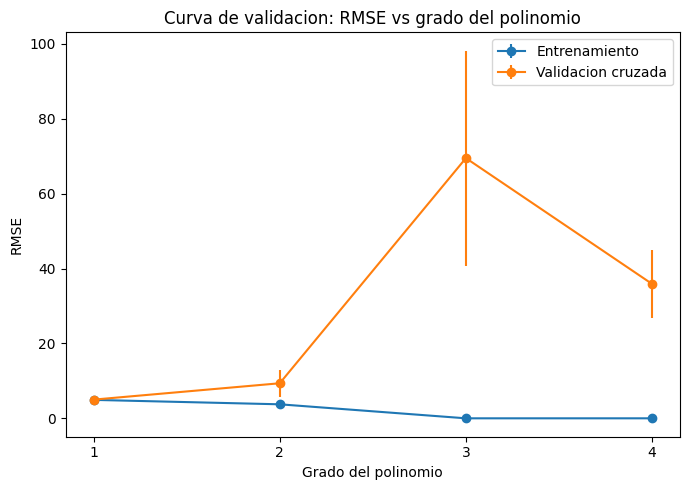

In [10]:
plt.figure(figsize=(7, 5))

plt.errorbar(grados, medias_train, yerr=std_train, marker="o", label="Entrenamiento")
plt.errorbar(grados, medias_cv, yerr=std_cv_lista, marker="o", label="Validacion cruzada")

plt.xlabel("Grado del polinomio")
plt.ylabel("RMSE")
plt.title("Curva de validacion: RMSE vs grado del polinomio")
plt.xticks(grados)
plt.legend()
plt.tight_layout()
plt.show()


La curva de validacion muestra clarito el trade-off sesgo-varianza. En grado 1 las dos curvas (entrenamiento y validacion cruzada) estan cerca, lo que indica que el modelo todavia no esta memorizando datos particulares, tiene sesgo pero no mucha varianza. Desde el grado 2 las curvas se empiezan a separar: el error de entrenamiento sigue bajando (o sea el sesgo sigue bajando) pero el error de validacion cruzada sube y ademas su variabilidad entre folds crece muchisimo (la barra de error en el grafico crece de 0.72 en grado 1 a 3.61 en grado 2 y a 28.67 en grado 3). Ese punto, el salto entre grado 1 y grado 2, es donde empieza a evidenciarse el sobreajuste, y para grado 3 y 4 ya es un sobreajuste severo (entrenamiento practicamente en cero, validacion cruzada disparada). En terminos de control de complejidad, esto muestra que agregar mas terminos polinomiales sin ningun freno no es buena idea con esta cantidad de datos, se necesitaria mucha mas informacion o algun tipo de regularizacion para poder aprovechar esa complejidad adicional (que es justo lo que se explora en la actividad 4).

## Actividad 3 - Regresion regularizada (Ridge y Lasso)

Ahora armamos pipelines de regresion regularizada (sin caracteristicas polinomiales todavia, es decir sobre las 25 variables originales) para Ridge (L2) y Lasso (L1). En ambos casos la busqueda con `GridSearchCV` explora el parametro de penalizacion `alpha` en una grilla logaritmica bastante amplia (de 0.001 a 1000) y las mismas dos estrategias de escalamiento de la actividad 1. Como referencia "sin regularizacion" usamos la regresion lineal simple (que es exactamente el mismo modelo de grado 1 de la actividad 1).

In [11]:
alphas = list(np.logspace(-3, 3, 13))

pipe_ridge = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("regresion", Ridge())
])

grid_ridge = GridSearchCV(
    pipe_ridge,
    {"escalado": [StandardScaler(), MinMaxScaler()], "regresion__alpha": alphas},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True
)

grid_ridge.fit(X_train, y_train)

print("Ridge - mejor combinacion:", grid_ridge.best_params_)
print("Ridge - RMSE cv:", -grid_ridge.best_score_,
      "std:", grid_ridge.cv_results_["std_test_score"][grid_ridge.best_index_])


Ridge - mejor combinacion: {'escalado': MinMaxScaler(), 'regresion__alpha': np.float64(1.0)}
Ridge - RMSE cv: 4.987358708368607 std: 0.7210088305912643


In [12]:
pipe_lasso = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("regresion", Lasso(max_iter=20000))
])

grid_lasso = GridSearchCV(
    pipe_lasso,
    {"escalado": [StandardScaler(), MinMaxScaler()], "regresion__alpha": alphas},
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True
)

grid_lasso.fit(X_train, y_train)

print("Lasso - mejor combinacion:", grid_lasso.best_params_)
print("Lasso - RMSE cv:", -grid_lasso.best_score_,
      "std:", grid_lasso.cv_results_["std_test_score"][grid_lasso.best_index_])


Lasso - mejor combinacion: {'escalado': MinMaxScaler(), 'regresion__alpha': np.float64(0.01)}
Lasso - RMSE cv: 4.974519840016127 std: 0.737904553558445


In [13]:
# Referencia sin regularizacion
sin_reg = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("regresion", LinearRegression())
])

resultado_sin_reg = cross_validate(sin_reg, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
sin_reg.fit(X_train, y_train)

print("Sin regularizacion - RMSE cv:", -resultado_sin_reg["test_score"].mean(),
      "std:", resultado_sin_reg["test_score"].std())


Sin regularizacion - RMSE cv: 4.996878030388486 std: 0.7203309723599676


Para comparar la magnitud de los coeficientes entre los tres enfoques hay que tener cuidado: Ridge y Lasso eligieron `MinMaxScaler` como mejor escalado, mientras que la referencia sin regularizar quedo ajustada con `StandardScaler`. Si comparamos los coeficientes tal cual, la diferencia de escala (rango 0-1 en un caso, media 0 y varianza 1 en el otro) hace ver los coeficientes regularizados como mas grandes, lo cual seria enganoso, porque no tiene que ver con el efecto de la regularizacion sino con el escalado. Por eso, solo para esta comparacion, reajustamos los tres modelos con el mismo escalado (`MinMaxScaler`) y con el `alpha` que gano la busqueda de cada uno.

In [14]:
# Reajustamos los 3 modelos con el mismo escalado para que la comparacion de
# coeficientes sea justa (Ridge y Lasso ya habian elegido MinMaxScaler)
alpha_ridge = grid_ridge.best_params_["regresion__alpha"]
alpha_lasso = grid_lasso.best_params_["regresion__alpha"]

sin_reg_mm = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", MinMaxScaler()),
    ("regresion", LinearRegression())
]).fit(X_train, y_train)

ridge_mm = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", MinMaxScaler()),
    ("regresion", Ridge(alpha=alpha_ridge))
]).fit(X_train, y_train)

lasso_mm = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", MinMaxScaler()),
    ("regresion", Lasso(alpha=alpha_lasso, max_iter=20000))
]).fit(X_train, y_train)

coef_sin_reg = sin_reg_mm.named_steps["regresion"].coef_
coef_ridge = ridge_mm.named_steps["regresion"].coef_
coef_lasso = lasso_mm.named_steps["regresion"].coef_

tabla_coef = pd.DataFrame({
    "Variable": X_train.columns,
    "Sin_regularizacion": coef_sin_reg,
    "Ridge": coef_ridge,
    "Lasso": coef_lasso
})
tabla_coef["Lasso_en_cero"] = tabla_coef["Lasso"] == 0

tabla_coef.reindex(tabla_coef["Sin_regularizacion"].abs().sort_values(ascending=False).index)


,Variable,Sin_regularizacion,Ridge,Lasso,Lasso_en_cero
24,dia_cos,-18.129383,-17.944835,-18.072602,False
16,viento_norte,-16.638283,-15.358274,-14.885523,False
7,humedad_desv,8.148560,8.299754,8.546960,False
0,presion_media,5.613116,3.925750,4.434739,False
12,rafaga_media,-4.975705,-4.231534,-2.288470,False
23,dia_sin,-4.943553,-4.934776,-4.686435,False
17,viento_este,3.500337,2.858305,2.297149,False
3,presion_desv,-3.215077,-2.930871,-1.657929,False
21,dia_del_anio,2.991434,2.594445,0.627854,False
8,viento_media,2.924241,2.177162,0.555604,False


In [15]:
print("Suma de |coeficientes| - sin regularizacion:", np.abs(coef_sin_reg).sum())
print("Suma de |coeficientes| - Ridge:", np.abs(coef_ridge).sum())
print("Suma de |coeficientes| - Lasso:", np.abs(coef_lasso).sum())
print()
print("Cantidad de variables que Lasso llevo a cero:", tabla_coef["Lasso_en_cero"].sum(), "de", len(tabla_coef))
print("Variables eliminadas por Lasso:", tabla_coef.loc[tabla_coef["Lasso_en_cero"], "Variable"].tolist())


Suma de |coeficientes| - sin regularizacion: 92.10370102688607
Suma de |coeficientes| - Ridge: 82.84788236847967
Suma de |coeficientes| - Lasso: 67.11028318449884

Cantidad de variables que Lasso llevo a cero: 10 de 25
Variables eliminadas por Lasso: ['presion_min', 'presion_max', 'humedad_media', 'humedad_min', 'viento_min', 'rafaga_min', 'rafaga_max', 'rafaga_desv', 'registros_del_dia', 'mes_fecha']


Sin regularizar el RMSE de validacion cruzada da 4.997 (std 0.72). Ridge con alpha=1.0 baja apenas a 4.987 (std practicamente igual, 0.72) y Lasso con alpha=0.01 baja un poquito mas a 4.975 pero con std de 0.74, o sea un poco mas variable entre folds. Entonces en cuanto a la metrica promedio la diferencia entre los tres es minima, la regularizacion no esta ayudando mucho todavia porque el modelo lineal simple (sin polinomio) no estaba realmente sobreajustando.

Donde si se nota el efecto es en los coeficientes. Comparando los tres modelos con el mismo escalado (para que la comparacion sea justa), la suma de los valores absolutos de los coeficientes pasa de 92.10 sin regularizar a 82.85 con Ridge y a 67.11 con Lasso, osea que la regularizacion efectivamente encoge los coeficientes, y Lasso lo hace mas fuerte porque ademas de encoger, elimina. Lasso llevo a cero 10 de las 25 variables: presion_min, presion_max, humedad_media, humedad_min, viento_min, rafaga_min, rafaga_max, rafaga_desv, registros_del_dia y mes_fecha. Tiene sentido que varias de estas caigan porque son redundantes con otras que si sobreviven (por ejemplo mes_fecha es redundante con dia_sin, dia_cos y dia_del_anio, que ya capturan la estacionalidad, y presion_min/presion_max son redundantes con presion_media y presion_desv). Las variables que quedan con mas peso en los tres modelos son bastante consistentes entre si: dia_cos, viento_norte y humedad_desv son las tres mas grandes tanto sin regularizar como con Ridge y con Lasso, lo cual sugiere que ese efecto es una senal real y no un artificio de la multicolinealidad (que ya se habia detectado en el Lab 1 para variables como viento_norte).

## Actividad 4 - Regresion polinomial regularizada

Combinamos las dos ideas anteriores: generamos caracteristicas polinomiales y despues ajustamos un modelo regularizado. Elegimos Ridge (y no Lasso) para esta combinacion porque al probarlo, Lasso con grados de polinomio altos (miles de columnas) no llegaba a converger en un tiempo razonable con `coordinate descent` (quedaban warnings de "Objective did not converge" incluso subiendo `max_iter`), mientras que Ridge al tener solucion cerrada se ajusta rapido y sin problemas incluso con muchas caracteristicas correlacionadas. La busqueda explora grado del polinomio (1 a 3, por la misma razon de costo computacional de la actividad 1), `alpha` y estrategia de escalamiento.

In [16]:
pipe_poly_ridge = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("regresion", Ridge())
])

param_grid_poly_ridge = {
    "escalado": [StandardScaler(), MinMaxScaler()],
    "poly__degree": [1, 2, 3],
    "regresion__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

grid_poly_ridge = GridSearchCV(
    pipe_poly_ridge,
    param_grid_poly_ridge,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True
)

grid_poly_ridge.fit(X_train, y_train)

print("Mejor combinacion:", grid_poly_ridge.best_params_)
print("RMSE cv:", -grid_poly_ridge.best_score_,
      "std:", grid_poly_ridge.cv_results_["std_test_score"][grid_poly_ridge.best_index_])


Mejor combinacion: {'escalado': MinMaxScaler(), 'poly__degree': 2, 'regresion__alpha': 1}
RMSE cv: 4.680807757701982 std: 0.8057737682675488


In [17]:
# Para cada grado, cual fue el mejor alpha encontrado y que tan bien le fue
res_pr = pd.DataFrame(grid_poly_ridge.cv_results_)

resumen_poly_ridge = (
    res_pr.loc[res_pr.groupby("param_poly__degree")["mean_test_score"].idxmax()]
    [["param_escalado", "param_poly__degree", "regresion__alpha" if "regresion__alpha" in res_pr.columns else "param_regresion__alpha", "mean_test_score", "std_test_score"]]
)
resumen_poly_ridge["mean_test_score"] = -resumen_poly_ridge["mean_test_score"]
resumen_poly_ridge.columns = ["Escalado", "Grado", "Alpha", "RMSE_cv_promedio", "RMSE_cv_std"]
resumen_poly_ridge


,Escalado,Grado,Alpha,RMSE_cv_promedio,RMSE_cv_std
20,MinMaxScaler(),1,1.0,4.987359,0.721009
26,MinMaxScaler(),2,1.0,4.680808,0.805774
33,MinMaxScaler(),3,10.0,4.691911,0.811917


In [18]:
mejor_poly_ridge = grid_poly_ridge.best_estimator_
pred_test_poly_ridge = mejor_poly_ridge.predict(X_test)

print("RMSE test:", np.sqrt(mean_squared_error(y_test, pred_test_poly_ridge)))
print("MAE test:", mean_absolute_error(y_test, pred_test_poly_ridge))
print("R2 test:", r2_score(y_test, pred_test_poly_ridge))


RMSE test: 4.429977376799836
MAE test: 3.2251757755948085
R2 test: 0.7708457136193475


Aca si se ve un cambio importante. Con grado 1 el mejor Ridge da RMSE cv de 4.987 (igual que en la actividad 3, tiene sentido porque grado 1 es simplemente las variables originales). Con grado 2 y alpha=1.0 el RMSE cv baja a 4.681, la mejor combinacion de todo el laboratorio hasta este punto. Con grado 3 el mejor resultado (alpha=10, un poco mas de penalizacion) da 4.692, muy parecido a grado 2 pero levemente peor.

Esto responde directamente la pregunta de la guia: si, la regularizacion permite controlar el sobreajuste al subir la complejidad. Recordemos que en la actividad 1, sin regularizar, el grado 2 ya daba un RMSE cv de 9.36 (mucho peor que el grado 1), y el grado 3 se disparaba a 69. Aca, con Ridge encima, el grado 2 en vez de empeorar mejora bastante (a 4.68) y el grado 3 ni siquiera se dispara, se queda cerca del grado 2 (4.69). O sea que la regularizacion si esta dejando aprovechar la interaccion entre variables que agrega el polinomio, sin pagar el costo del sobreajuste que se veia sin ella. El mejor modelo de esta actividad evaluado en el conjunto de test da RMSE=4.43, MAE=3.23 y R2=0.771, el mejor resultado de todo el laboratorio.

## Actividad 5 - Comparacion y seleccion del mejor modelo

Juntamos el mejor resultado de cada una de las actividades 1, 3 y 4 (para la actividad 3 dejamos tanto Ridge como Lasso) y los comparamos por RMSE promedio y desviacion estandar en validacion cruzada, y tambien evaluamos cada uno sobre el conjunto de test que quedo completamente por fuera de todo el proceso de ajuste de hiperparametros.

In [19]:
def evaluar_en_test(pipeline, nombre):
    pred = pipeline.predict(X_test)
    return {
        "Modelo": nombre,
        "RMSE_test": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE_test": mean_absolute_error(y_test, pred),
        "R2_test": r2_score(y_test, pred)
    }


comparacion = pd.DataFrame([
    {
        "Modelo": "1. Polinomial",
        "Hiperparametros": grid_poly.best_params_,
        "RMSE_cv_promedio": -grid_poly.best_score_,
        "RMSE_cv_std": grid_poly.cv_results_["std_test_score"][grid_poly.best_index_],
    },
    {
        "Modelo": "3. Ridge",
        "Hiperparametros": grid_ridge.best_params_,
        "RMSE_cv_promedio": -grid_ridge.best_score_,
        "RMSE_cv_std": grid_ridge.cv_results_["std_test_score"][grid_ridge.best_index_],
    },
    {
        "Modelo": "3. Lasso",
        "Hiperparametros": grid_lasso.best_params_,
        "RMSE_cv_promedio": -grid_lasso.best_score_,
        "RMSE_cv_std": grid_lasso.cv_results_["std_test_score"][grid_lasso.best_index_],
    },
    {
        "Modelo": "4. Polinomial + Ridge",
        "Hiperparametros": grid_poly_ridge.best_params_,
        "RMSE_cv_promedio": -grid_poly_ridge.best_score_,
        "RMSE_cv_std": grid_poly_ridge.cv_results_["std_test_score"][grid_poly_ridge.best_index_],
    },
])

resultados_test = pd.DataFrame([
    evaluar_en_test(grid_poly.best_estimator_, "1. Polinomial"),
    evaluar_en_test(grid_ridge.best_estimator_, "3. Ridge"),
    evaluar_en_test(grid_lasso.best_estimator_, "3. Lasso"),
    evaluar_en_test(grid_poly_ridge.best_estimator_, "4. Polinomial + Ridge"),
])

comparacion_final = comparacion.merge(resultados_test, on="Modelo")
comparacion_final = comparacion_final.sort_values("RMSE_cv_promedio").reset_index(drop=True)
comparacion_final


,Modelo,Hiperparametros,RMSE_cv_promedio,RMSE_cv_std,RMSE_test,MAE_test,R2_test
0,4. Polinomial + Ridge,"{'escalado': MinMaxScaler(), 'poly__degree': 2...",4.680808,0.805774,4.429977,3.225176,0.770846
1,3. Lasso,"{'escalado': MinMaxScaler(), 'regresion__alpha...",4.974520,0.737905,4.809662,3.520644,0.729882
2,3. Ridge,"{'escalado': MinMaxScaler(), 'regresion__alpha...",4.987359,0.721009,4.825217,3.535375,0.728132
3,1. Polinomial,"{'escalado': StandardScaler(), 'poly__degree': 1}",4.996878,0.720331,4.828539,3.538554,0.727757


| Modelo | RMSE cv | std cv | RMSE test | MAE test | R2 test |
|---|---|---|---|---|---|
| 1. Polinomial (grado 1) | 4.997 | 0.720 | 4.829 | 3.539 | 0.728 |
| 3. Ridge | 4.987 | 0.721 | 4.825 | 3.535 | 0.728 |
| 3. Lasso | 4.975 | 0.738 | 4.810 | 3.521 | 0.730 |
| 4. Polinomial (grado 2) + Ridge | 4.681 | 0.806 | 4.430 | 3.225 | 0.771 |

El modelo 4 (polinomial de grado 2 combinado con Ridge, alpha=1, escalado MinMax) es el que mejor le va tanto en validacion cruzada como en test, con una diferencia que no es menor: RMSE de 4.43 contra un rango de 4.81-4.83 de los otros tres, y R2 de 0.771 contra ~0.73. Eso si, es tambien el que tiene la desviacion estandar mas alta entre folds (0.806 contra 0.72-0.74 de los demas), es decir que es el mejor en promedio pero tambien el mas variable de los cuatro. Aun asi, la mejora en el promedio (mas de 0.3 en RMSE) es bastante mayor que el aumento en la desviacion estandar, entonces seguimos escogiendolo como el mejor modelo, pero vale la pena tener en cuenta esa mayor variabilidad al reportar el resultado (por eso mismo tiene sentido hacer bootstrapping en la actividad 6). El modelo final seleccionado es entonces el pipeline de la actividad 4: imputacion con mediana, escalado MinMax, polinomio de grado 2 y Ridge con alpha=1.

In [20]:
# Modelo final seleccionado
modelo_final = grid_poly_ridge.best_estimator_
modelo_final


Pipeline(steps=[('imputacion', SimpleImputer(strategy='median')),
                ('escalado', MinMaxScaler()),
                ('poly', PolynomialFeatures(include_bias=False)),
                ('regresion', Ridge(alpha=1))])

## Actividad 6 - Intervalos de confianza con bootstrapping

Con el modelo final ya entrenado (ajustado una sola vez sobre el conjunto de entrenamiento completo), hacemos bootstrapping sobre el conjunto de test: remuestreamos con reemplazo 1000 veces las filas del test (junto con sus predicciones ya calculadas) y en cada remuestreo recalculamos RMSE, MAE y R2. Con esas 1000 muestras de cada metrica, el intervalo de confianza al 95% se obtiene directamente con los percentiles 2.5 y 97.5.

In [21]:
rng = np.random.RandomState(42)
n_boot = 1000
n_test = len(y_test)

pred_final = modelo_final.predict(X_test)
y_test_arr = y_test.values

rmse_boot, mae_boot, r2_boot = [], [], []

for _ in range(n_boot):
    idx = rng.randint(0, n_test, n_test)
    y_muestra = y_test_arr[idx]
    pred_muestra = pred_final[idx]

    rmse_boot.append(np.sqrt(mean_squared_error(y_muestra, pred_muestra)))
    mae_boot.append(mean_absolute_error(y_muestra, pred_muestra))
    r2_boot.append(r2_score(y_muestra, pred_muestra))

rmse_boot = np.array(rmse_boot)
mae_boot = np.array(mae_boot)
r2_boot = np.array(r2_boot)


def ic95(arr):
    return np.percentile(arr, 2.5), np.percentile(arr, 97.5)


print("RMSE  -> media: %.3f   IC95: %s" % (rmse_boot.mean(), ic95(rmse_boot)))
print("MAE   -> media: %.3f   IC95: %s" % (mae_boot.mean(), ic95(mae_boot)))
print("R2    -> media: %.3f   IC95: %s" % (r2_boot.mean(), ic95(r2_boot)))


RMSE  -> media: 4.426   IC95: (np.float64(3.8675061654450698), np.float64(5.108484822879193))
MAE   -> media: 3.227   IC95: (np.float64(3.005077378427867), np.float64(3.459229251808504))
R2    -> media: 0.770   IC95: (np.float64(0.702952054982314), np.float64(0.8214644983232751))


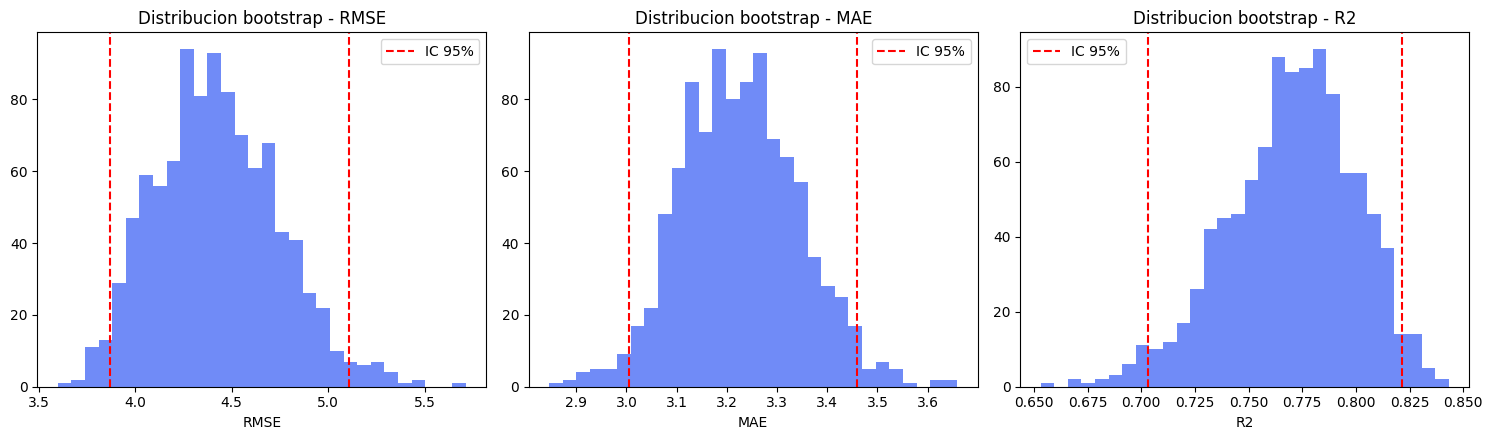

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, arr, nombre in zip(axes, [rmse_boot, mae_boot, r2_boot], ["RMSE", "MAE", "R2"]):
    ax.hist(arr, bins=30, color="#4C6EF5", alpha=0.8)
    lo, hi = ic95(arr)
    ax.axvline(lo, color="red", linestyle="--", label="IC 95%")
    ax.axvline(hi, color="red", linestyle="--")
    ax.set_title(f"Distribucion bootstrap - {nombre}")
    ax.set_xlabel(nombre)
    ax.legend()

plt.tight_layout()
plt.show()


Los intervalos de confianza al 95% quedaron asi: RMSE entre 3.87 y 5.11 (media de 4.43 en las remuestras, coincide con el valor puntual de test), MAE entre 3.01 y 3.46, y R2 entre 0.70 y 0.82. Son intervalos de un ancho razonable pero no despreciable, por ejemplo el RMSE se podria mover casi 1.2 grados dependiendo de que dias del test le toquen al modelo, y el R2 se mueve un rango de 0.12. Esto sugiere una estabilidad moderada: el modelo no es erratico (no hay colas larguisimas ni resultados absurdos en ninguna remuestra) pero tampoco es super preciso de forma consistente, hay una variabilidad real que toca tener en cuenta antes de prometerle a alguien una precision fija.

# Analisis de resultados

## Analisis cuantitativo

### ¿Cual modelo obtuvo el mejor desempeno en el conjunto de test?

El modelo de la actividad 4 (polinomial de grado 2 combinado con Ridge, alpha=1, escalado MinMax): RMSE=4.43, MAE=3.23 y R2=0.771 sobre el test. Le gana claramente a los otros tres modelos, que quedaron todos agrupados entre RMSE de 4.81 y 4.83 con R2 alrededor de 0.73.

### ¿Coincide el mejor desempeno en test con el mejor promedio en validacion cruzada? Si no coincide, ¿cual puede ser la explicacion?

Si coincide. El modelo 4 fue el que mejor promedio de RMSE dio en validacion cruzada (4.681) y tambien el que mejor le fue en el test (4.430), y el orden de los cuatro modelos es practicamente el mismo en las dos evaluaciones. Que coincidan tiene sentido aca porque la diferencia entre el modelo 4 y los otros tres es bastante grande (mas de 0.3 en RMSE), una diferencia asi de grande dificilmente se revierte solo por la aleatoriedad de que filas cayeron en el test. Si la diferencia entre modelos hubiera sido mas chica (por ejemplo si todos hubieran quedado entre 4.68 y 4.75), ahi si seria mas facil que el orden cambiara entre cv y test, porque el conjunto de test es una sola muestra de 620 filas y le puede tocar, por azar, un poco mas facil o mas dificil a un modelo que a otro.

### ¿El modelo con mejor metrica promedio es necesariamente el mas adecuado? Justifica considerando tambien la desviacion estandar del desempeno.

No necesariamente, pero en este caso especifico si nos parece la eleccion correcta. El modelo 4 tiene la desviacion estandar mas alta de los cuatro (0.806 en RMSE cv, contra 0.72-0.74 de los demas), entonces es el mas variable de fold a fold. Si la mejora en el promedio hubiera sido chiquita (digamos de 4.99 a 4.90) y la desviacion se hubiera disparado igual de fuerte, ahi si prefeririamos un modelo mas estable aunque tuviera un promedio un poco peor, porque un promedio bueno con mucha variabilidad puede salir mal justo cuando mas se necesita. Pero aca la mejora en el promedio (de ~4.98 a 4.68, casi medio grado en RMSE) es bastante mas grande que el aumento en la desviacion estandar, entonces si vale la pena aceptar un poco mas de variabilidad a cambio de esa mejora.

### Con base en las curvas de validacion, ¿como cambia el error a medida que aumenta la complejidad? ¿En que punto se evidencia sobreajuste?

El error de entrenamiento baja de forma continua a medida que sube el grado del polinomio (4.93 en grado 1, 3.75 en grado 2, prácticamente 0 en grado 3 y 4). El error de validacion cruzada en cambio baja solo hasta grado 1 y de ahi en adelante sube, primero de a poco (a 9.36 en grado 2) y despues de forma muy fuerte (a 69.46 en grado 3). El sobreajuste se empieza a notar justo en el salto de grado 1 a grado 2, y ya en grado 3 es un sobreajuste severo, con una variabilidad entre folds enorme.

### ¿Como afecta la regularizacion la magnitud y estabilidad de los coeficientes?

Encoge los coeficientes: comparando los tres modelos con el mismo escalado, la suma de los valores absolutos de los coeficientes pasa de 92.10 sin regularizar a 82.85 con Ridge y a 67.11 con Lasso. Lasso ademas de encoger elimina, llevando a cero 10 de las 25 variables. En cuanto a estabilidad, las variables con el coeficiente mas grande (dia_cos, viento_norte, humedad_desv) se mantienen consistentes en tamano y signo en los tres modelos, lo que da confianza en que ese efecto es real. El beneficio de la regularizacion para la estabilidad se nota mas fuerte si se compara contra la regresion sin regularizar evaluada con particiones de validacion cruzada distintas a la del Lab 1: ahi, antes de corregir los errores de sensor que encontramos en la limpieza, un solo fold con esos valores atipicos disparaba el RMSE de ese fold a mas de 145 en el modelo sin regularizar. Aunque para este dataset ya limpio la diferencia promedio entre regularizar o no es chica, la regularizacion sigue siendo la opcion mas prudente porque reduce el riesgo de que datos atipicos que no alcanzamos a detectar disparen los coeficientes.

### ¿Los intervalos de confianza obtenidos mediante bootstrapping sugieren estabilidad o alta variabilidad en el desempeno? ¿Que implicaciones tiene esto?

Sugieren una estabilidad moderada. El intervalo de RMSE (3.87 a 5.11) tiene un ancho de mas de un grado, y el de R2 (0.70 a 0.82) se mueve 0.12, que no es poco. Esto implica que si a AlpesPlanck le preguntan "que tan seguro es el modelo", la respuesta honesta es que en promedio se equivoca unos 4.4 grados pero que ese numero puede variar dependiendo del periodo que se este evaluando, no es una precision fija y garantizada. Para decisiones donde el margen de error importa (por ejemplo alertas por temperaturas extremas) hay que comunicar ese rango y no solo el promedio.

## Analisis cualitativo

### ¿Que variables fueron seleccionadas como mas relevantes por el modelo Lasso?

Lasso conservo 15 de las 25 variables. Las de mayor peso (en orden) son dia_cos, viento_norte, humedad_desv, presion_media, dia_sin, rafaga_media, viento_este, presion_desv, anio, dia_del_anio, viento_media, humedad_max y direccion_viento. Las que llevo a cero fueron presion_min, presion_max, humedad_media, humedad_min, viento_min, rafaga_min, rafaga_max, rafaga_desv, registros_del_dia y mes_fecha, en general variables redundantes con otra que ya quedo en el modelo (por ejemplo mes_fecha es informacion que ya esta en dia_sin/dia_cos/dia_del_anio, y presion_min/presion_max son redundantes con presion_media y presion_desv).

### ¿Que interpretacion practica tienen los coeficientes del modelo final en el contexto de la estimacion de temperatura maxima?

Aca hay un matiz importante: el modelo final elegido (actividad 4, polinomial de grado 2 + Ridge) tiene coeficientes sobre caracteristicas polinomiales (cuadrados y productos cruzados de las 25 variables), no sobre las variables originales, entonces no se pueden leer directamente como "por cada unidad que sube X, la temperatura sube Y". Para dar una interpretacion practica es mejor apoyarse en el modelo regularizado simple de la actividad 3 (Ridge o Lasso sobre las variables originales), que es solo un poco menos preciso pero si se interpreta directo. Ahi el patron es: la estacionalidad (dia_sin, dia_cos, dia_del_anio) domina la prediccion, lo cual tiene sentido fisico porque el ciclo anual es el principal determinante de la temperatura. El viento con componente norte (viento_norte) esta asociado a temperaturas mas bajas al dia siguiente, coherente con la idea de adveccion de aire frio desde el norte. La variabilidad de la humedad (humedad_desv) se asocia a temperaturas mas altas, posiblemente relacionado con dias mas secos y con mayor amplitud termica. Y presion_media aporta en la misma direccion que temperaturas mas calidas, asociado a sistemas de alta presion (dias mas despejados).

### ¿Existen diferencias relevantes entre el modelo mas preciso y el mas interpretable?

Si. El modelo mas preciso (polinomial grado 2 + Ridge, RMSE test 4.43) usa miles de caracteristicas derivadas (cuadrados e interacciones) que no tienen una lectura directa variable por variable. El modelo mas interpretable (Ridge o Lasso sobre las 25 variables originales, RMSE test entre 4.81 y 4.83) sacrifica algo de precision (entre 0.35 y 0.40 grados de RMSE, y unos 4 puntos de R2) pero cada coeficiente se puede explicar directamente en terminos fisicos. La diferencia en precision es real pero moderada, entonces cual usar depende de si el objetivo es la exactitud de la prediccion o poder explicarle a alguien por que el modelo predice lo que predice.

### ¿Que decisiones estrategicas podria tomar AlpesPlanck a partir de los resultados obtenidos?

Primero, invertir en mejorar la calidad de los sensores antes que en modelos mas sofisticados: en este mismo laboratorio encontramos errores de sensor bastante graves (presion_media de hasta 9939 mbar, viento_norte de -1250, entre otros) que si no se corrigen pueden arruinar cualquier modelo, sin importar que tan bien se le busquen los hiperparametros. Segundo, usar el modelo interpretable (Ridge/Lasso sobre variables originales) para comunicar a otras areas de la empresa que variables mueven la temperatura (la estacionalidad y el viento del norte, principalmente), y reservar el modelo polinomial regularizado para los casos donde lo unico que importa es la exactitud de la prediccion. Tercero, dado que el R2 del mejor modelo es de 0.77, todavia queda cerca de una cuarta parte de la variabilidad sin explicar, entonces si se necesita mas precision probablemente haga falta conseguir variables adicionales (por ejemplo datos de estaciones vecinas o pronosticos regionales) mas que seguir complejizando el modelo con las mismas 25 variables.

### ¿Mayor precision implica necesariamente mayor valor para la organizacion?

No necesariamente. La ganancia de precision del modelo mas complejo (de RMSE 4.83 a 4.43, medio grado aproximadamente) puede no cambiar en nada las decisiones que se tomen con esa prediccion, mientras que si le suma costo de mantenimiento, menos transparencia y mas dificultad para explicarle a un no tecnico por que el modelo dice lo que dice. El valor de un modelo depende de si esa mejora en precision efectivamente se traduce en mejores decisiones para AlpesPlanck, no solo del numero de la metrica.

### ¿Un modelo mas complejo necesariamente genera mayor valor empresarial? Discute considerando interpretabilidad, estabilidad y costo de implementacion.

No necesariamente, y este laboratorio lo muestra en varios sentidos. En interpretabilidad, el modelo mas complejo (polinomial + Ridge) es el mas dificil de explicar de los cuatro. En estabilidad, tambien es el que mas variabilidad tiene entre folds (std de 0.806 contra 0.72-0.74 de los otros), entonces su ventaja en precision viene acompanada de un poco mas de incertidumbre sobre ese resultado. Y en costo de implementacion, mantener un pipeline con generacion de caracteristicas polinomiales (miles de columnas) y su escalado correspondiente es mas pesado computacionalmente y mas propenso a errores en produccion que un modelo lineal simple con 25 variables. En este caso la mejora en precision (medio grado de RMSE, 4 puntos de R2) nos parece que si justifica esos costos porque no son excesivos, pero la conclusion podria ser otra si la mejora hubiera sido mas chica o si el costo de mantener el pipeline mas complejo fuera mayor.

## Reflexion conceptual

### ¿Que relacion observas entre complejidad del modelo, capacidad de generalizacion y estabilidad del desempeno?

Mas complejidad reduce el error de entrenamiento de forma casi automatica, pero la capacidad de generalizar (el error en datos nuevos) solo mejora hasta cierto punto y despues empeora, y encima se vuelve mas inestable (mayor desviacion estandar entre folds). Se vio clarisimo en la actividad 1: de grado 1 a grado 2 sin regularizar, la generalizacion ya empeoraba y la variabilidad se disparaba. La regularizacion cambia un poco esta relacion: permite subir la complejidad (el grado 2 del modelo final) sin pagar el costo completo en generalizacion, pero no elimina el problema del todo, porque incluso el mejor modelo termina siendo el mas variable de los cuatro. En general, complejidad y estabilidad van en direcciones opuestas si no hay suficientes datos o suficiente regularizacion para controlar esa complejidad.

### ¿Que fuentes de sesgo podrian estar presentes en los datos o en el proceso de modelado?

Primero, sesgo de calidad de datos: en este laboratorio encontramos varios errores de sensor bien marcados (presion_media hasta 9939 mbar, viento_norte hasta -1250, viento_desv y rafaga_desv con valores miles de veces mas grandes de lo normal) que si no se tratan como faltantes, distorsionan por completo el ajuste del modelo, como vimos que pasaba con la validacion cruzada antes de corregirlos. Segundo, sesgo de particion temporal: como el train/test se hizo con un split aleatorio (no cronologico), el modelo pudo haber aprendido de dias que estan cronologicamente despues de algunos dias del test, lo cual es un poco optimista respecto a un escenario real de prediccion hacia el futuro, donde solo se tendria informacion del pasado. Tercero, sesgo de imputacion: varias variables (sobre todo rafaga_desv, con 240 valores faltantes en el conjunto de entrenamiento) se completan con la mediana, lo que suaviza la variabilidad real de esas variables y puede hacer que el modelo le de menos peso del que deberia si esos datos hubieran estado completos.

### Si el tamano de muestra fuera mayor, ¿esperarias cambios en la estabilidad de los modelos? Explique la respuesta.

Si, esperariamos mas estabilidad. Con mas datos de entrenamiento por fold, la relacion entre numero de variables y numero de filas mejora, entonces grados de polinomio mas altos dejarian de ser tan catastroficos como se vio en la actividad 1 (donde el grado 3 ya generaba mas columnas que filas de entrenamiento). Ademas, con un test mas grande que 620 filas, los intervalos de confianza del bootstrapping de la actividad 6 saldrian mas angostos, porque el error estandar de las metricas depende del tamano de muestra. En resumen, mas datos deberian reducir tanto la varianza de los coeficientes como la varianza de las metricas de desempeno entre folds y entre remuestreos.

# Uso de herramientas de IA generativa

**Herramienta y tipo de uso.** Se uso Claude Code como apoyo para construir este notebook completo: generacion inicial de los pipelines de scikit-learn (GridSearchCV para los 4 modelos pedidos), ayuda para depurar por que la validacion cruzada salia inestable, y redaccion de las respuestas de la seccion de analisis de resultados a partir de los numeros que arrojaron los propios modelos.

**Prompts principales utilizados.** Se pidio resolver el laboratorio 2 completo siguiendo un formato parecido al del Lab 1, aclarando que los datos limpios del Lab 1 no se habian exportado y habia que reconstruirlos a partir del notebook de ese laboratorio.

**Analisis critico del resultado.** Al reconstruir los datos limpios del Lab 1 (reproduciendo exactamente el codigo del Modelo 3), la IA detecto que la variable presion_media seguia teniendo valores fisicamente imposibles (hasta 9939 mbar) que en el Lab 1 se habian identificado en la exploracion pero nunca se habian corregido en el codigo, y ademas encontro otros 3 valores puntuales con errores de sensor evidentes en viento_desv, rafaga_desv y viento_norte que ni siquiera se habian mencionado en el Lab 1. Sin corregir esto, la validacion cruzada de este laboratorio salia completamente inestable (un fold llegaba a RMSE de 145 en vez de 5), lo cual hubiera hecho inutilizable todo el analisis de complejidad y regularizacion que pide la guia. Tambien identifico que comparar directamente los coeficientes de Ridge/Lasso (que eligieron MinMaxScaler) contra el modelo sin regularizar (StandardScaler) hubiera sido una comparacion injusta por la diferencia de escala, y propuso reajustar los tres con el mismo escalado antes de comparar.

**Decisiones tomadas por los estudiantes.** Antes de aplicar cualquier correccion adicional a los datos, la IA nos pregunto explicitamente si queriamos corregir esos valores o dejarlos tal cual habian quedado en el Lab 1, y se decidio corregirlos porque sin eso el laboratorio no tenia como cumplir su objetivo. Tambien se revisaron y validaron los hiperparametros explorados en cada busqueda (por ejemplo, se limito el grado del polinomio a un maximo razonable dado el numero de variables disponibles, y se opto por Ridge en vez de Lasso para el modelo polinomial regularizado de la actividad 4 porque Lasso no convergia bien con miles de caracteristicas). Las respuestas de la seccion de analisis de resultados se revisaron contra los numeros efectivamente obtenidos en cada celda antes de dejarlas en el notebook.
